# Texas Housing Activity

How does monthly sales volume differ across cities?

Data: [ggplot2/txhousing](https://vincentarelbundock.github.io/Rdatasets/doc/ggplot2/txhousing.html)

This notebook performs a descriptive analysis on a real historical dataset. Source limitations: Mean monthly sales depends on city size and available months; missing months are not zero sales.

In [1]:
from pathlib import Path
from analysis import run
result = run(Path.cwd())
result["manifest"]

Out[0]: 
{'project': 'Texas Housing Activity',
 'executed_utc': '2026-11-21T10:14:10.612394+00:00',
 'source': 'https://vincentarelbundock.github.io/Rdatasets/csv/ggplot2/txhousing.csv',
 'documentation': 'https://vincentarelbundock.github.io/Rdatasets/doc/ggplot2/txhousing.html',
 'sha256': 'dcd1d3d019f3a29dd4d3906334e05bc9080d9f2f52f10d302e9f6c258592a53d',
 'raw_rows': 8602,
 'analysis_rows': 8034,
 'excluded_rows': 568,
 'exact_duplicate_rows': 0,
 'duplicates_policy': 'Retained; duplicate values do not necessarily mean duplicate entities.',
 'python': '3.12.14',
 'pandas': '2.2.3',
 'numpy': '2.3.5',
 'matplotlib': '3.10.8'}


## Data quality
Missing required variables are excluded, not silently imputed. Repeated rows are preserved; review the source observation grain.

In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv("outputs/quality_audit.csv"))

,column,dtype,missing,missing_pct,distinct
0,rownames,int64,0,0.000000,8602
1,city,object,0,0.000000,46
2,year,int64,0,0.000000,16
3,month,int64,0,0.000000,12
4,sales,float64,568,6.603116,1711
5,volume,float64,568,6.603116,7494
6,median,float64,616,7.161125,1537
7,listings,float64,1424,16.554290,3702
8,inventory,float64,1467,17.054173,295
9,date,float64,0,0.000000,187


## SQL and analysis
Complete-case descriptive comparison of sales by city; show group counts, mean, minimum and maximum.

In [3]:
print(Path("analysis.sql").read_text())
display(result["table"].head(30))
print(result["finding"])

SELECT "city" AS segment, COUNT(*) AS rows_used, AVG("sales") AS metric, MIN("sales") AS minimum, MAX("sales") AS maximum FROM observations GROUP BY "city" ORDER BY "city";

The largest observed mean sales is 5,582.882 for Houston. This ranking is descriptive, not a recommendation.


,segment,rows_used,metric,minimum,maximum
0,Abilene,187,150.486631,68.0,268.0
1,Amarillo,187,238.652406,67.0,390.0
2,Arlington,187,423.983957,173.0,720.0
3,Austin,187,1996.689840,914.0,3466.0
4,Bay Area,187,502.614973,230.0,849.0
5,Beaumont,187,177.058824,83.0,318.0
6,Brazoria County,173,94.231214,31.0,165.0
7,Brownsville,185,65.518919,23.0,130.0
8,Bryan-College Station,187,186.743316,55.0,414.0
9,Collin County,187,1084.983957,464.0,1861.0


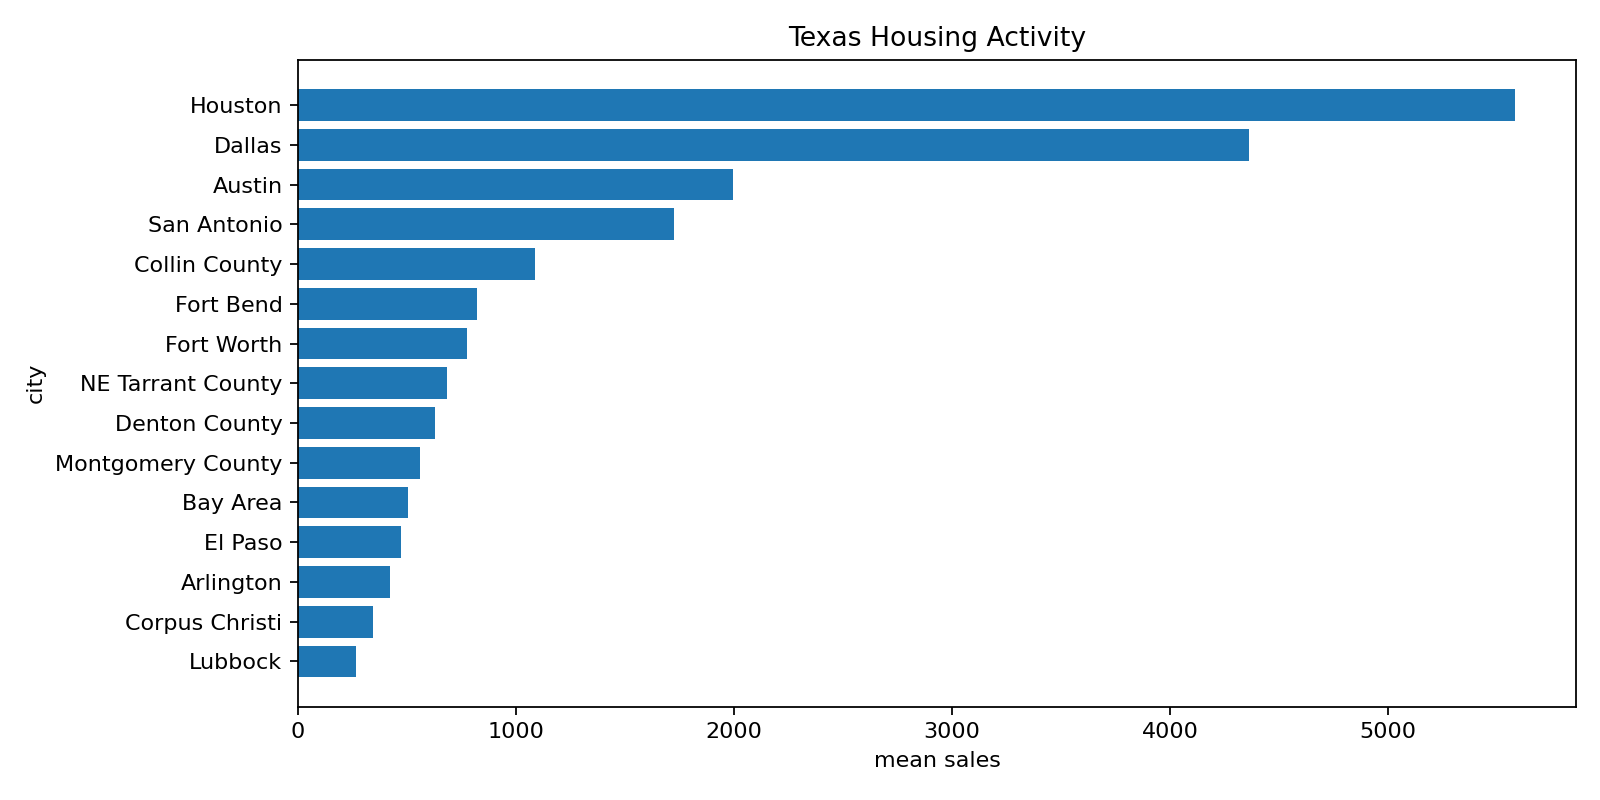

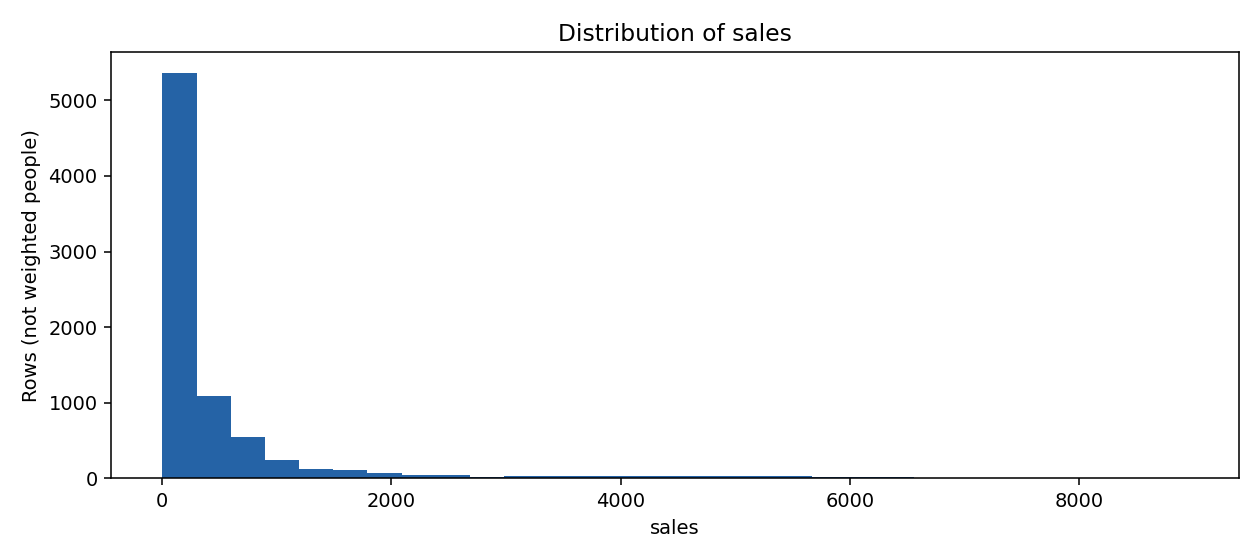

In [4]:
display(Image(filename="outputs/main_chart.png"))
display(Image(filename="outputs/distribution.png"))

## Interpretation
Mean monthly sales depends on city size and available months; missing months are not zero sales.

**Next action:** Compare matched calendar periods and normalise by housing stock.

Read outputs/REPORT.md for executed findings. This project does not establish causation or a production decision rule.